# Chart CNN baseline — 5-minute US equities

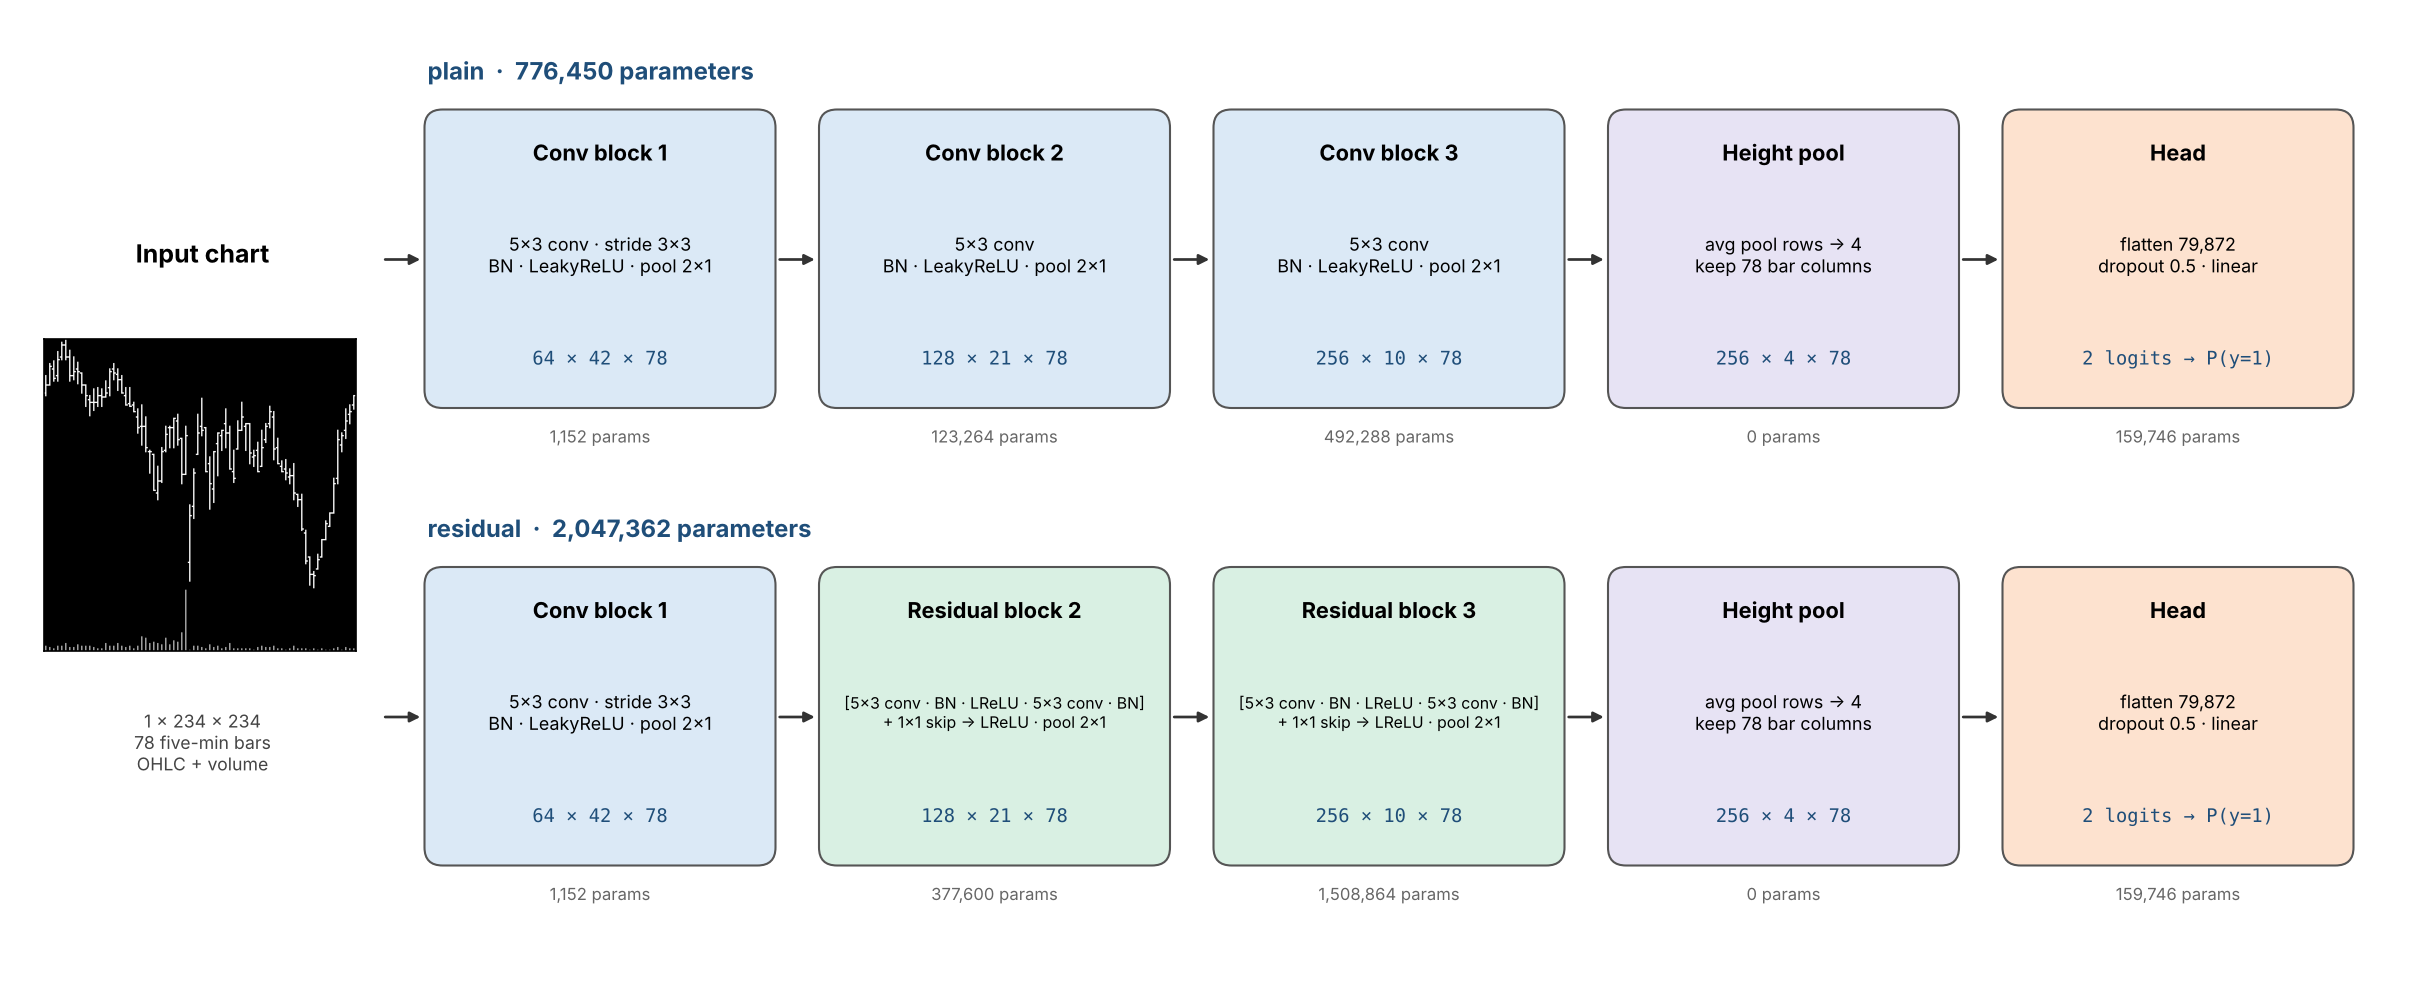

- **Input**: one trading day (78 five-minute bars) drawn as a 234×234 OHLC + volume chart.
- **Models**: `plain` (Jiang–Kelly–Xiu style, top) and `residual` (blocks 2–3 become ResNet basic blocks with a skip connection, bottom), plus `series1d`: a 1D CNN fed the same windows as raw OHLCV numbers (no image), to test whether the picture itself helps.
- **Targets**: `vol_h1` (is the next bar's move larger than usual?) and `xsdir_h12` (does the stock beat the cross-sectional median over the next hour?).
- **Benchmarks**: training prior, simple rules, gradient-boosted trees on hand-made features.
- **Code**: all logic lives in `chartcnn/` next to this notebook; cells only configure, run and plot.
- **Drive layout**: `Demo/cnn78u_colab_bundle.zip` (data) and `Demo/CNN-Relevant/` (this notebook, `chartcnn/`, `runs/`).

## 1. Setup

Mounted at /content/drive
chartcnn 2026-11-13.4 loaded from /content/drive/MyDrive/Colab Notebooks/EC/Project/Demo/CNN-Relevant/chartcnn/__init__.py
data: /content/chartcnn___n9u0a6/bundle/prepared | device: cuda


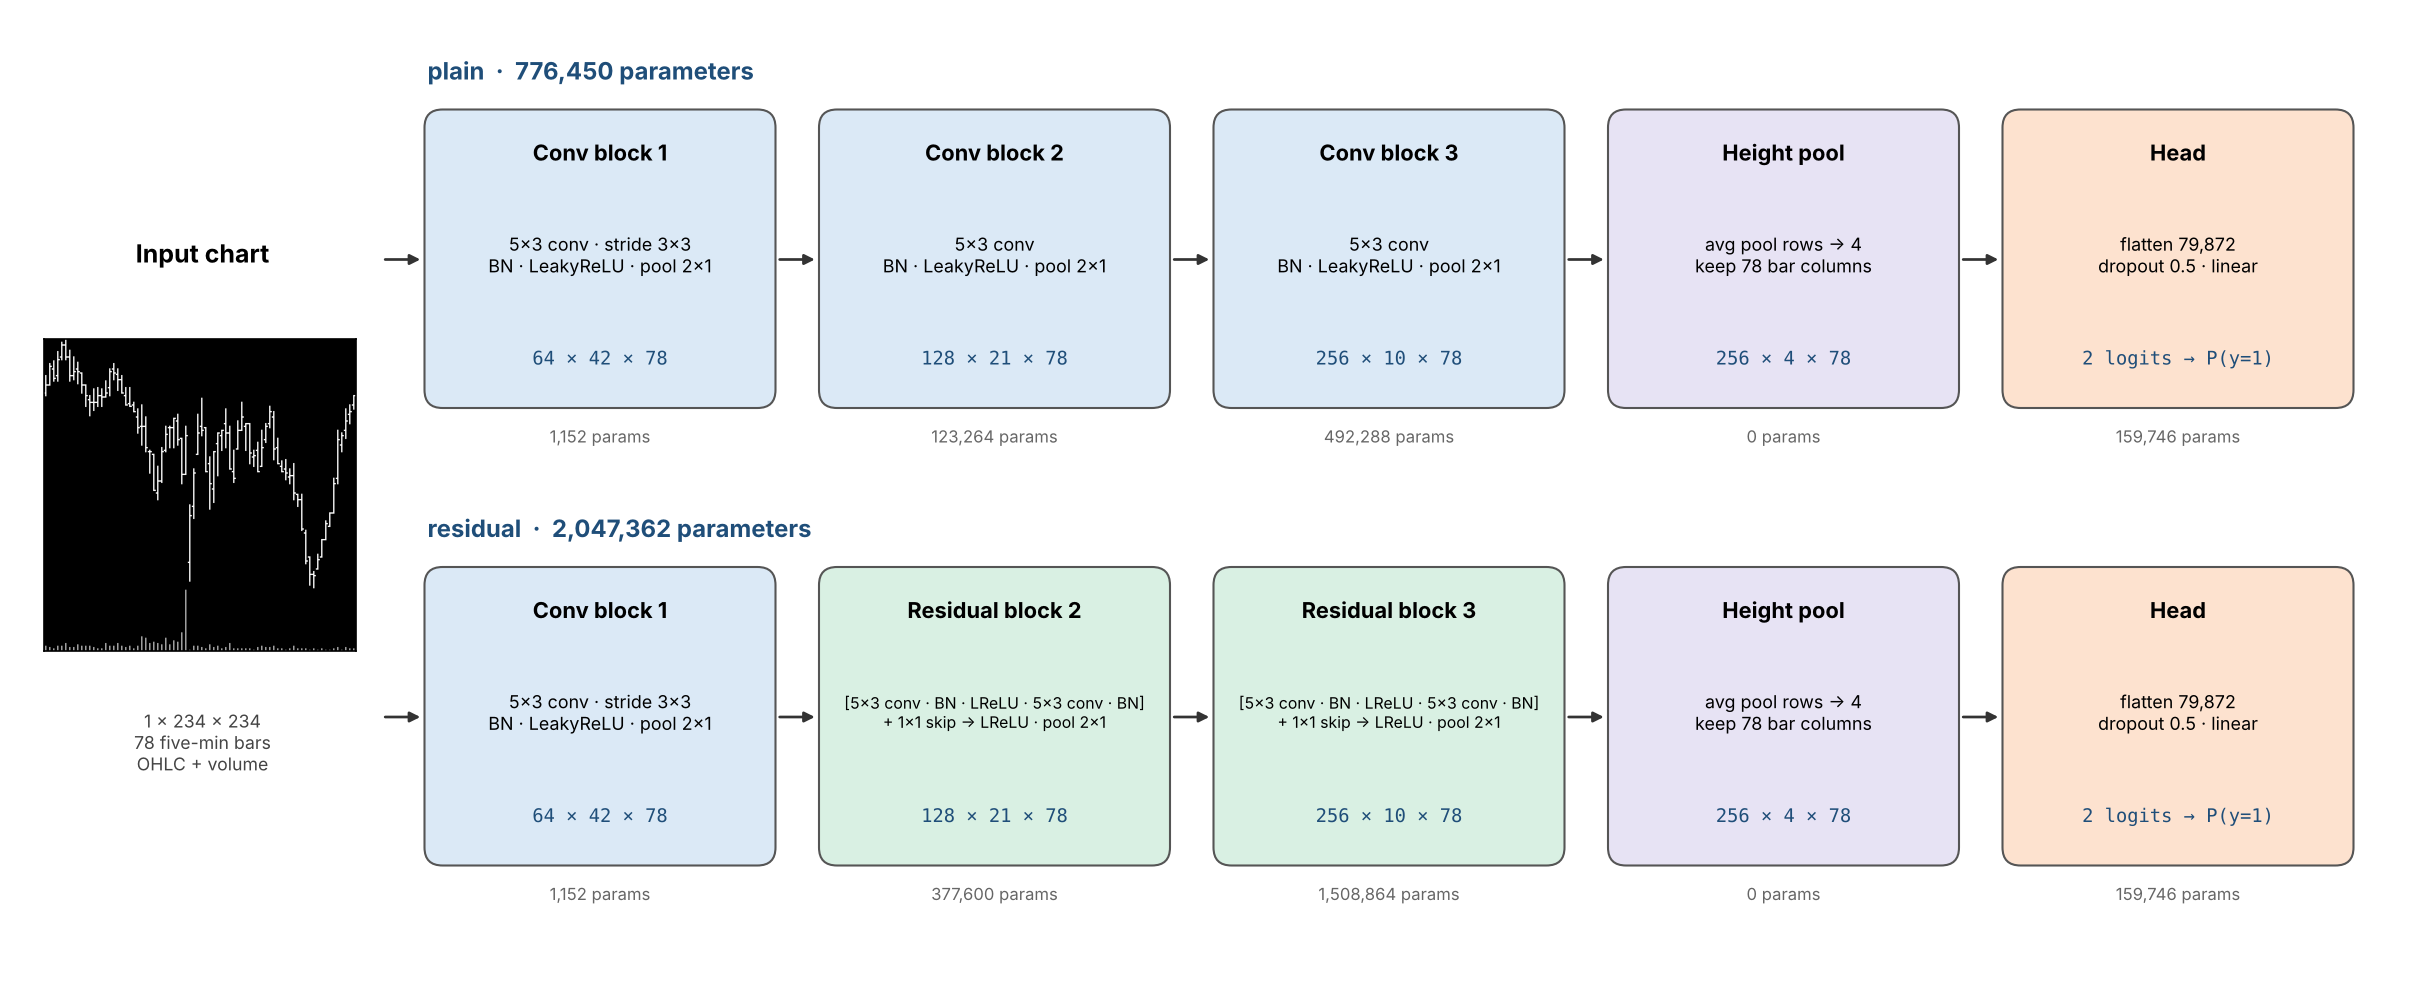

In [1]:
import os, sys, shutil, tempfile
from pathlib import Path

LOCAL_TEST = os.environ.get("CNN78U_LOCAL_NOTEBOOK_TEST") == "1"     # repository QA only
if LOCAL_TEST:
    DEMO = Path(os.environ["CNN78U_LOCAL_DEMO"])
else:
    from google.colab import drive
    drive.mount("/content/drive")
    DEMO = Path("/content/drive/MyDrive/Colab Notebooks/EC/Project/Demo")
DRIVE = DEMO / "CNN-Relevant"                     # this notebook, chartcnn/ and run outputs
sys.path.insert(0, str(DRIVE))                    # makes CNN-Relevant/chartcnn importable

import numpy as np, pandas as pd, torch
from IPython.display import display
import chartcnn
from chartcnn import analysis, frame_corr, plots
from chartcnn.training import run_experiment, evaluate_test
from chartcnn.utils import stage_bundle, save_json

LOCAL = Path(tempfile.mkdtemp(prefix="chartcnn_", dir=None if LOCAL_TEST else "/content"))
PREPARED = stage_bundle(DEMO, LOCAL / "bundle")  # unzip data to fast local disk
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("data:", PREPARED, "| device:", DEVICE)
from IPython.display import Image
display(Image(filename=str(DRIVE / "assets" / "network_flow.png"), width=1000))   # network flow (also at the top)

## 2. Configuration
Change settings here only. Set `RESUME=True` with the old `RUN_ID` to continue after a disconnect.

In [2]:
from datetime import datetime, timezone
SMOKE = LOCAL_TEST                                # tiny code check; never a result
assert DEVICE.type == "cuda" or SMOKE, "Select a GPU runtime"

SETTINGS = dict(
    learning_rate=1e-5, weight_decay=0.0,         # Adam, as in Jiang-Kelly-Xiu
    batch_size=4 if SMOKE else 128, eval_batch_size=8 if SMOKE else 512,
    epochs=1 if SMOKE else 12, patience=2, min_delta=1e-5,   # early stop on validation log loss
    stride=6,                                     # one sample per stock every 30 minutes
    channels=[64, 128, 256], head_height=4, dropout=0.5,
    num_workers=0 if SMOKE else min(8, os.cpu_count() or 2),
    seed=69,
)
EXPERIMENTS = [
    dict(name="vol_h1", target="vol", horizon=1),                    # sanity check: signal is known to exist
    dict(name="xsdir_h12", target="xs_dir", horizon=12, stride=12),  # 1-hour relative direction; stride =
]                                                                    # horizon so labels do not overlap
ARCHS = ["plain", "residual", "series1d"]         # image CNN, image ResNet, 1D CNN on raw OHLCV (no image)
RESUME, RUN_ID = False, "local_smoke" if LOCAL_TEST else datetime.now(timezone.utc).strftime("run_%Y%m%d_%H%M%S")
RUN_DRIVE, RUN_LOCAL = DRIVE / "runs" / RUN_ID, LOCAL / "run"
if RESUME:
    shutil.copytree(RUN_DRIVE, RUN_LOCAL)
else:
    assert LOCAL_TEST or not RUN_DRIVE.exists(), "RUN_ID exists: pick a new one or set RESUME=True"
    RUN_DRIVE.mkdir(parents=True, exist_ok=True); RUN_LOCAL.mkdir()
save_json(RUN_LOCAL / "settings.json", dict(settings=SETTINGS, experiments=EXPERIMENTS, archs=ARCHS), RUN_DRIVE)
print("results ->", RUN_DRIVE)

results -> /content/drive/MyDrive/Colab Notebooks/EC/Project/Demo/CNN-Relevant/runs/run_20261114_020923


## 3. Models
Layer-by-layer output shapes and parameter counts for every architecture. Output layers start at zero, so every initial prediction is exactly 0.5.

In [3]:
store = chartcnn.Store(PREPARED)
sample, _ = chartcnn.build_split(store, "train", "vol", 1, SETTINGS["stride"])
for arch in ARCHS:
    data = chartcnn.make_dataset(PREPARED, sample.head(4), arch)
    x = torch.stack([data[i][0] for i in range(4)])
    model = chartcnn.build_model(dict(SETTINGS, arch=arch))
    table, total, trainable = chartcnn.parameter_table(model)
    print(f"{arch}: {total:,} parameters ({trainable:,} trainable)")
    display(table)
    print("initial P(y=1):", model.eval()(x).softmax(1)[:, 1].tolist(), "\n")
del model

plain: 776,450 parameters (776,450 trainable)


,layer,output_shape,parameters
0,0: Conv2d,"(64, 84, 78)",1024
1,1: BatchNorm2d,"(64, 84, 78)",128
2,2: LeakyReLU,"(64, 84, 78)",0
3,3: MaxPool2d,"(64, 42, 78)",0
4,4: Conv2d,"(128, 42, 78)",123008
5,5: BatchNorm2d,"(128, 42, 78)",256
6,6: LeakyReLU,"(128, 42, 78)",0
7,7: MaxPool2d,"(128, 21, 78)",0
8,8: Conv2d,"(256, 21, 78)",491776
9,9: BatchNorm2d,"(256, 21, 78)",512


initial P(y=1): [0.5, 0.5, 0.5, 0.5] 

residual: 2,047,362 parameters (2,047,362 trainable)


,layer,output_shape,parameters
0,0: Conv2d,"(64, 84, 78)",1024
1,1: BatchNorm2d,"(64, 84, 78)",128
2,2: LeakyReLU,"(64, 84, 78)",0
3,3: MaxPool2d,"(64, 42, 78)",0
4,4: ResidualBlock,"(128, 21, 78)",377600
5,5: ResidualBlock,"(256, 10, 78)",1508864
6,6: AdaptiveAvgPool2d,"(256, 4, 78)",0
7,head.0: Flatten,"(79872,)",0
8,head.1: Dropout,"(79872,)",0
9,head.2: Linear,"(2,)",159746


initial P(y=1): [0.5, 0.5, 0.5, 0.5] 

series1d: 720,770 parameters (720,770 trainable)


,layer,output_shape,parameters
0,0: Conv1d,"(128, 78)",3328
1,1: BatchNorm1d,"(128, 78)",256
2,2: LeakyReLU,"(128, 78)",0
3,3: Conv1d,"(256, 78)",164096
4,4: BatchNorm1d,"(256, 78)",512
5,5: LeakyReLU,"(256, 78)",0
6,6: Conv1d,"(384, 78)",491904
7,7: BatchNorm1d,"(384, 78)",768
8,8: LeakyReLU,"(384, 78)",0
9,head.0: Flatten,"(29952,)",0


initial P(y=1): [0.5, 0.5, 0.5, 0.5] 



## 4. Frame correlation (data)
A *frame* is one chart image. With stride 6, frame *t* and frame *t+6* share 72 of 78 bars, and all stocks at one timestamp share the market's move. Both make the effective sample size much smaller than the image count.

,lag,bars_shared,pixel_raw,pixel_aligned
0,1,77,0.472,0.942
1,2,76,0.348,0.893
2,3,75,0.294,0.851
3,6,72,0.226,0.745
4,12,66,0.170,0.616
5,24,54,0.132,0.473
6,39,39,0.115,0.335
7,78,0,0.158,NaN
8,156,0,0.154,NaN


,experiment,icc,stride,samples,time_series_factor,cross_section_factor,effective_samples
0,vol_h1,0.134,1,1720524,6.07,49.33,5744
1,vol_h1,0.134,6,286754,1.86,49.33,3121
2,vol_h1,0.134,12,143377,1.33,49.33,2189
3,vol_h1,0.134,78,22058,1.16,49.33,386
4,xsdir_h12,0.000,1,1693641,9.23,1.00,183413
5,xsdir_h12,0.000,6,282273,1.75,1.00,160911
6,xsdir_h12,0.000,12,141136,1.05,1.00,134353
7,xsdir_h12,0.000,78,21713,1.01,1.00,21576


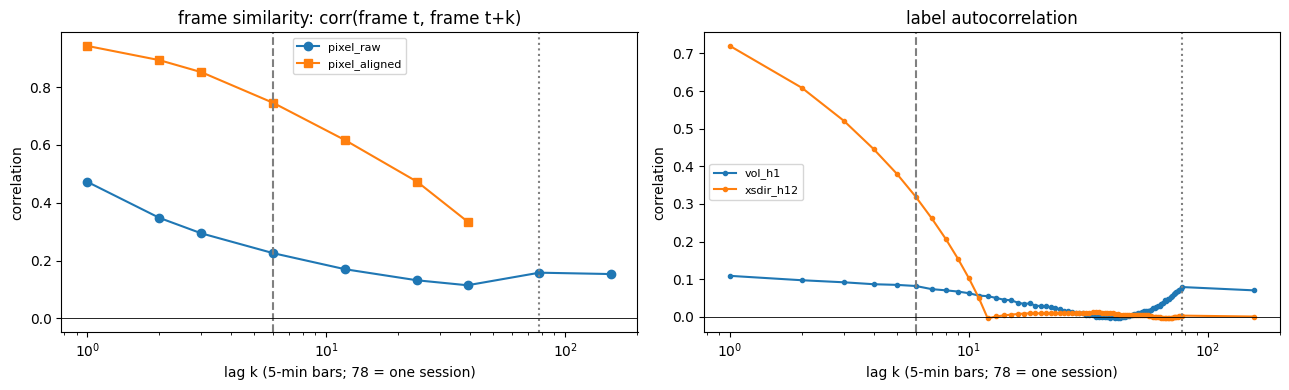

In [4]:
LAGS = frame_corr.DEFAULT_LAGS
anchors = frame_corr.sample_anchors(store, "validation", 64 if SMOKE else 400, LAGS)
similarity = frame_corr.image_similarity(PREPARED, anchors, LAGS)

label_acf, ess = {}, []
for exp in EXPERIMENTS:
    acf, frame, _ = frame_corr.label_autocorrelation(store, exp["target"], exp["horizon"], "train",
                                                     list(range(1, 79)) + [156])
    icc, m = frame_corr.cross_sectional_share(frame)
    a = acf.set_index("lag").label_autocorr
    ess += [dict(experiment=exp["name"], icc=round(icc, 4),
                 **frame_corr.effective_sample_size(len(frame), s, a, icc, m)) for s in (1, 6, 12, 78)]
    label_acf[exp["name"]] = acf

display(similarity.round(3))
display(pd.DataFrame(ess))
plots.plot_frame_corr(similarity, label_acf, SETTINGS["stride"], RUN_LOCAL / "frame_corr_data.png")

## 5. Train and validate
Per experiment: build labels → fit baselines → train the CNN → compare on validation. Watch `val AUC`, the log-loss gain vs prior (must be > 0) and `prob std` (≈ 0 means collapse).

In [ ]:
RESULTS = {}
for exp in EXPERIMENTS:
    for arch in ARCHS:
        key = f"{exp['name']}_{arch}"
        print("\n" + "=" * 25, key, "=" * 25)
        RESULTS[key] = run_experiment(PREPARED, exp, dict(SETTINGS, arch=arch), DEVICE,
                                      RUN_LOCAL / key, RUN_DRIVE / key, smoke=SMOKE)
        display(RESULTS[key]["table"].round(4))
        print("top-minus-bottom decile:", RESULTS[key]["long_short"])

# One row per (experiment, architecture): the CNN next to its strongest baseline.
summary = pd.DataFrame([dict(run=k, cnn_auc=r["table"].loc["CNN", "roc_auc"],
                             hgb_auc=r["table"].loc["hgb_hand_features", "roc_auc"],
                             cnn_log_loss_gain_pct=r["table"].loc["CNN", "log_loss_gain_vs_prior_pct"],
                             best_epoch=int(r["history"].loc[r["history"].val_log_loss.idxmin(), "epoch"]))
                        for k, r in RESULTS.items()])
display(summary.round(4)); summary.to_csv(RUN_LOCAL / "summary.csv", index=False)


========================= vol_h1_plain =========================
vol_h1 [plain, stride 6]: 287,689 train / 84,834 validation samples; positive share 0.500 / 0.398
HGB baseline: 18,300 tree nodes (300 trees, 20 features)
model (plain): 776,450 parameters (776,450 trainable)
  batch 449/2248  loss 0.6620  acc 0.5980  1103 img/s
  batch 898/2248  loss 0.6559  acc 0.6050  1110 img/s
  batch 1347/2248  loss 0.6520  acc 0.6106  1109 img/s
  batch 1796/2248  loss 0.6500  acc 0.6128  1110 img/s
  batch 2245/2248  loss 0.6487  acc 0.6139  1110 img/s
epoch 1: train_loss 0.6487 | val AUC 0.6906 | val log loss 0.6315 (+8.90% vs prior) | prob std 0.158
  batch 449/2248  loss 0.6392  acc 0.6265  1105 img/s
  batch 898/2248  loss 0.6399  acc 0.6255  1108 img/s
  batch 1347/2248  loss 0.6409  acc 0.6243  1109 img/s
  batch 1796/2248  loss 0.6408  acc 0.6244  1110 img/s
  batch 2245/2248  loss 0.6402  acc 0.6246  1111 img/s
epoch 2: train_loss 0.6402 | val AUC 0.6891 | val log loss 0.6207 (+10.46% vs 

,samples,positive_fraction,accuracy,balanced_accuracy,roc_auc,log_loss,prob_std,log_loss_gain_vs_prior_pct
model,,,,,,,,
CNN,84834,0.3976,0.6758,0.6407,0.6871,0.6138,0.1715,11.4437
training_prior,84834,0.3976,0.6024,0.5000,0.5000,0.6931,0.0000,0.0000
rule_recent_abs_return,84834,NaN,NaN,NaN,0.6096,NaN,NaN,NaN
hgb_hand_features,84834,0.3976,0.6783,0.6496,0.7045,0.6093,0.1725,12.0957


top-minus-bottom decile: {'cnn': None, 'hgb': None}

========================= vol_h1_residual =========================
vol_h1 [residual, stride 6]: 287,689 train / 84,834 validation samples; positive share 0.500 / 0.398
HGB baseline: 18,300 tree nodes (300 trees, 20 features)
model (residual): 2,047,362 parameters (2,047,362 trainable)
  batch 449/2248  loss 0.6676  acc 0.5876  506 img/s
  batch 898/2248  loss 0.6612  acc 0.5987  507 img/s
  batch 1347/2248  loss 0.6573  acc 0.6046  508 img/s
  batch 1796/2248  loss 0.6551  acc 0.6070  508 img/s
  batch 2245/2248  loss 0.6538  acc 0.6083  508 img/s
epoch 1: train_loss 0.6538 | val AUC 0.6859 | val log loss 0.6408 (+7.56% vs prior) | prob std 0.157
  batch 449/2248  loss 0.6416  acc 0.6243  508 img/s
  batch 898/2248  loss 0.6423  acc 0.6228  508 img/s
  batch 1347/2248  loss 0.6433  acc 0.6214  508 img/s
  batch 1796/2248  loss 0.6433  acc 0.6210  508 img/s
  batch 2245/2248  loss 0.6431  acc 0.6212  508 img/s
epoch 2: train_loss 0.6

,samples,positive_fraction,accuracy,balanced_accuracy,roc_auc,log_loss,prob_std,log_loss_gain_vs_prior_pct
model,,,,,,,,
CNN,84834,0.3976,0.6657,0.6410,0.6847,0.6255,0.1644,9.7584
training_prior,84834,0.3976,0.6024,0.5000,0.5000,0.6931,0.0000,0.0000
rule_recent_abs_return,84834,NaN,NaN,NaN,0.6096,NaN,NaN,NaN
hgb_hand_features,84834,0.3976,0.6783,0.6496,0.7045,0.6093,0.1725,12.0957


top-minus-bottom decile: {'cnn': None, 'hgb': None}

========================= vol_h1_series1d =========================
vol_h1 [series1d, stride 6]: 287,689 train / 84,834 validation samples; positive share 0.500 / 0.398
HGB baseline: 18,300 tree nodes (300 trees, 20 features)
model (series1d): 720,770 parameters (720,770 trainable)
  batch 449/2248  loss 0.6501  acc 0.6124  23407 img/s
  batch 898/2248  loss 0.6464  acc 0.6164  25498 img/s
  batch 1347/2248  loss 0.6434  acc 0.6203  26118 img/s
  batch 1796/2248  loss 0.6419  acc 0.6226  26736 img/s
  batch 2245/2248  loss 0.6404  acc 0.6241  26991 img/s
epoch 1: train_loss 0.6404 | val AUC 0.6905 | val log loss 0.6209 (+10.43% vs prior) | prob std 0.162
  batch 449/2248  loss 0.6328  acc 0.6353  25513 img/s
  batch 898/2248  loss 0.6328  acc 0.6355  26719 img/s
  batch 1347/2248  loss 0.6331  acc 0.6349  27266 img/s
  batch 1796/2248  loss 0.6327  acc 0.6349  27692 img/s
  batch 2245/2248  loss 0.6319  acc 0.6357  28063 img/s
epoch 

,samples,positive_fraction,accuracy,balanced_accuracy,roc_auc,log_loss,prob_std,log_loss_gain_vs_prior_pct
model,,,,,,,,
CNN,84834,0.3976,0.6693,0.6425,0.6905,0.6209,0.1619,10.4287
training_prior,84834,0.3976,0.6024,0.5000,0.5000,0.6931,0.0000,0.0000
rule_recent_abs_return,84834,NaN,NaN,NaN,0.6096,NaN,NaN,NaN
hgb_hand_features,84834,0.3976,0.6783,0.6496,0.7045,0.6093,0.1725,12.0957


... (4 outputs left out)

top-minus-bottom decile: {'cnn': {'days': 19, 'mean_bps': 1.2564225165125544, 't_stat': 0.5617999118347997}, 'hgb': {'days': 19, 'mean_bps': 1.9345893810845616, 't_stat': 0.5453562596015612}}

========================= xsdir_h12_series1d =========================
xsdir_h12 [series1d, stride 12]: 141,946 train / 41,402 validation samples; positive share 0.500 / 0.500
HGB baseline: 14,762 tree nodes (242 trees, 20 features)
model (series1d): 720,770 parameters (720,770 trainable)
  batch 221/1109  loss 0.6946  acc 0.5057  20776 img/s
  batch 442/1109  loss 0.6947  acc 0.5046  23657 img/s
  batch 663/1109  loss 0.6942  acc 0.5078  24542 img/s
  batch 884/1109  loss 0.6941  acc 0.5098  25127 img/s
  batch 1105/1109  loss 0.6939  acc 0.5115  25662 img/s
epoch 1: train_loss 0.6939 | val AUC 0.4949 | val log loss 0.6972 (-0.58% vs prior) | prob std 0.037
  batch 221/1109  loss 0.6898  acc 0.5323  25268 img/s
  batch 442/1109  loss 0.6898  acc 0.5333  26395 img/s
  batch 663/1109  loss 0.6895 

,samples,positive_fraction,accuracy,balanced_accuracy,roc_auc,log_loss,prob_std,log_loss_gain_vs_prior_pct
model,,,,,,,,
CNN,41402,0.5,0.4933,0.4933,0.4949,0.6972,0.0372,-0.5808
training_prior,41402,0.5,0.5000,0.5000,0.5000,0.6931,0.0000,0.0000
rule_last_bar_return,41402,NaN,NaN,NaN,0.4865,NaN,NaN,NaN
rule_78bar_momentum,41402,NaN,NaN,NaN,0.4923,NaN,NaN,NaN
hgb_hand_features,41402,0.5,0.5038,0.5038,0.5030,0.6957,0.0373,-0.3696


top-minus-bottom decile: {'cnn': {'days': 19, 'mean_bps': -0.5091154237559382, 't_stat': -0.1930163134540057}, 'hgb': {'days': 19, 'mean_bps': 1.9345893810845616, 't_stat': 0.5453562596015612}}


,run,cnn_auc,hgb_auc,cnn_log_loss_gain_pct,best_epoch
0,vol_h1_plain,0.6871,0.7045,11.4437,4
1,vol_h1_residual,0.6847,0.7045,9.7584,2
2,vol_h1_series1d,0.6905,0.7045,10.4287,1
3,xsdir_h12_plain,0.5079,0.5030,-0.1981,2
4,xsdir_h12_residual,0.4987,0.5030,-0.4832,1
5,xsdir_h12_series1d,0.4949,0.5030,-0.5808,1


## 6. Results

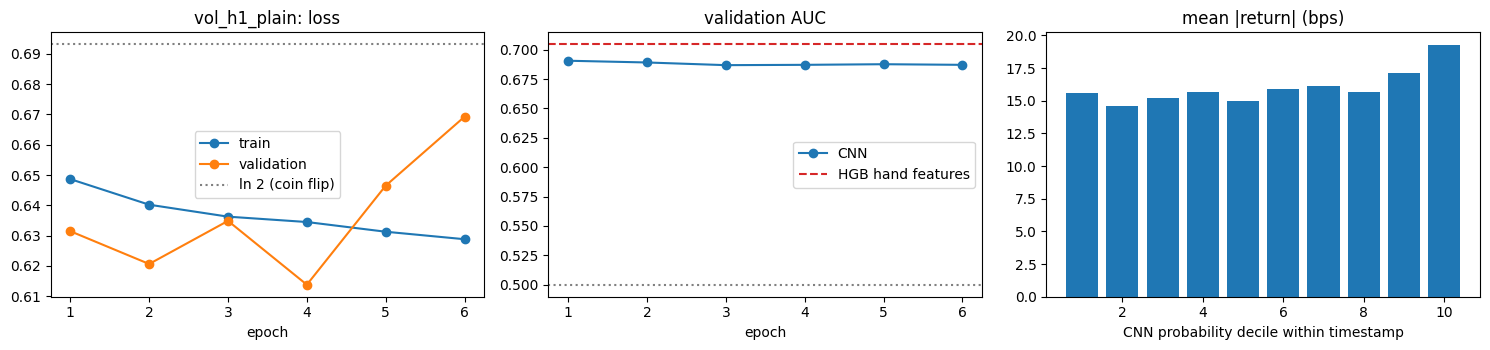

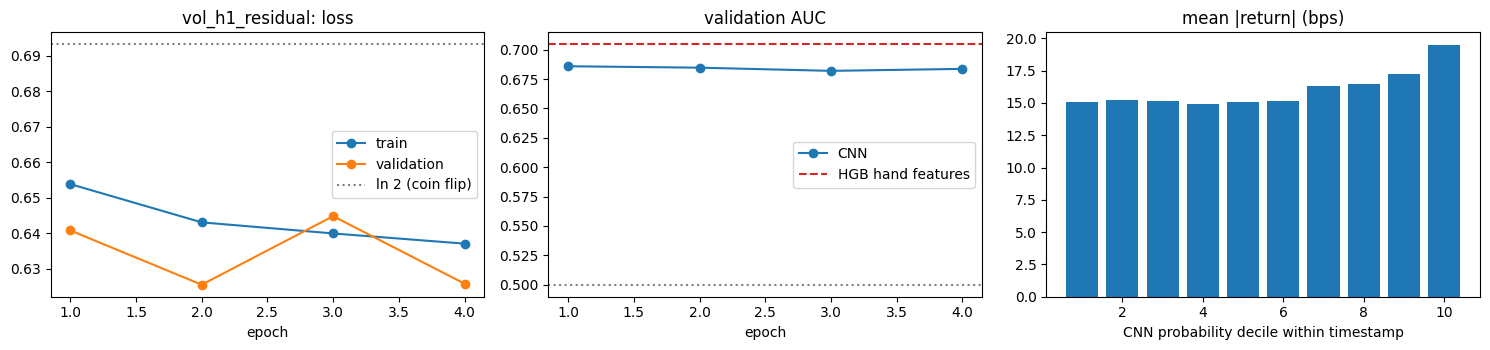

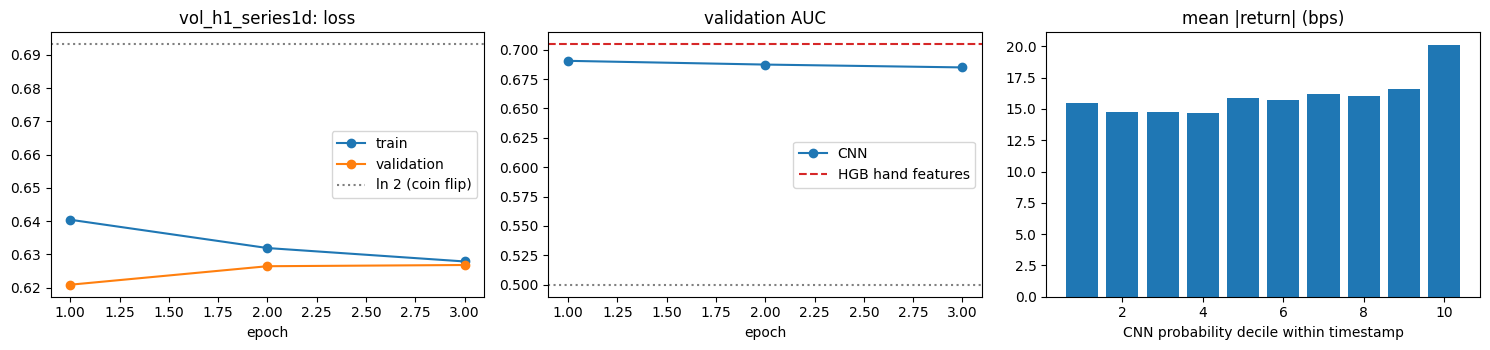

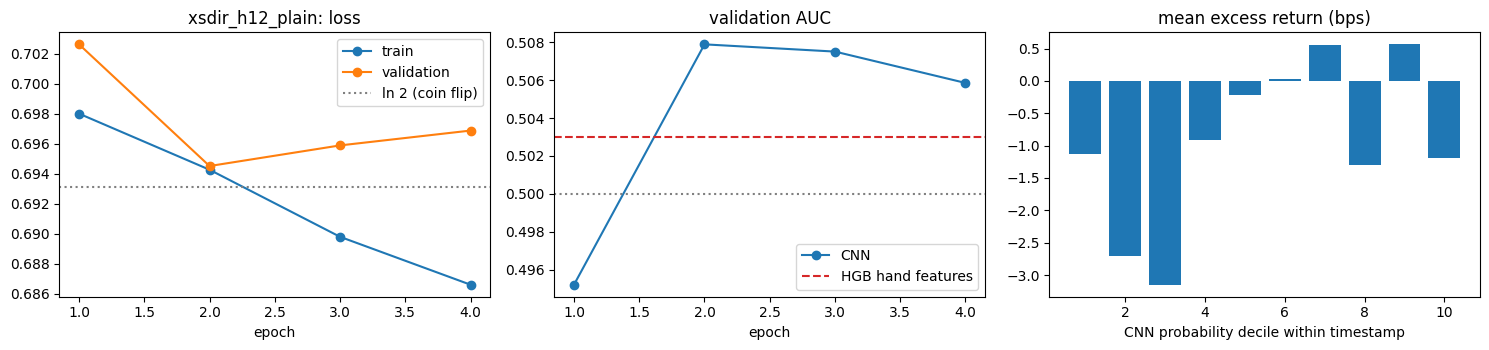

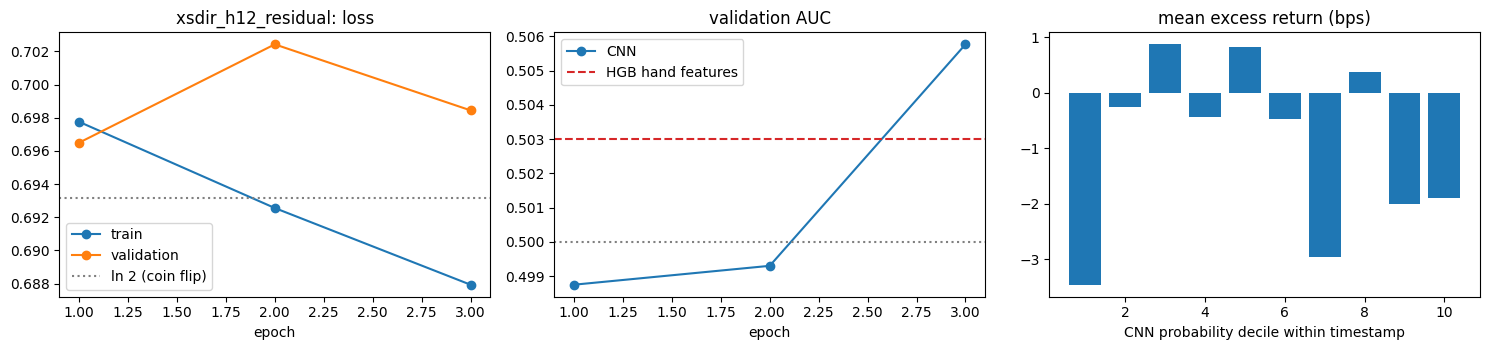

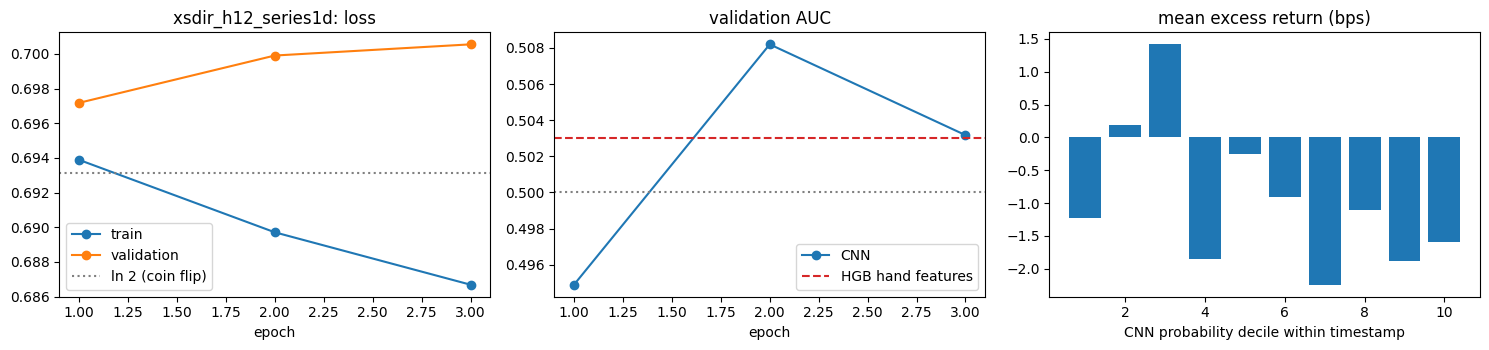

In [ ]:
for name, result in RESULTS.items():
    plots.plot_experiment(name, result, RUN_LOCAL / f"{name}_curves.png")

## 7. Analysis
Plain vs residual and CNN vs baselines, per target. Intervals come from resampling whole validation days (frames within a day are strongly correlated, see section 4). The takeaways below are generated from the numbers.

roc_auc  auc_ci_low  auc_ci_high  \
experiment model                                                            
vol_h1     CNN (plain)                    0.6871      0.6756       0.6981   
           CNN (residual)                 0.6847      0.6731       0.6967   
           CNN (series1d)                 0.6905      0.6776       0.7032   
           HGB hand features              0.7045      0.6921       0.7166   
           rule: rule_recent_abs_return   0.6096      0.6010       0.6166   
xsdir_h12  CNN (plain)                    0.5079      0.5024       0.5145   
           CNN (residual)                 0.4987      0.4909       0.5073   
           CNN (series1d)                 0.4949      0.4830       0.5074   
           HGB hand features              0.5030      0.4933       0.5126   
           rule: rule_78bar_momentum      0.4923      0.4758       0.5133   

                                         accuracy  balanced_accuracy  \
experiment model                                                       
vol_h1     CNN (plain)                     0.6758             0.6407   
           CNN (residual)                  0.6657             0.6410   
           CNN (series1d)                  0.6693             0.6425   
           HGB hand features               0.6783             0.6496   
           rule: rule_recent_abs_return       NaN                NaN   
xsdir_h12  CNN (plain)                     0.5073             0.5073   
           CNN (residual)                  0.4986             0.4986   
           CNN (series1d)                  0.4933             0.4933   
           HGB hand features               0.5038             0.5038   
           rule: rule_78bar_momentum          NaN                NaN   

                                         log_loss_gain_vs_prior_pct  prob_std  \
experiment model                                                                
vol_h1     CNN (plain)                                      11.4437    0.1715   
           CNN (residual)                                    9.7584    0.1644   
           CNN (series1d)                                   10.4287    0.1619   
           HGB hand features                                12.0957    0.1725   
           rule: rule_recent_abs_return                         NaN       NaN   
xsdir_h12  CNN (plain)                                      -0.1981    0.0322   
           CNN (residual)                                   -0.4832    0.0331   
           CNN (series1d)                                   -0.5808    0.0372   
           HGB hand features                                -0.3696    0.0373   
           rule: rule_78bar_momentum                            NaN       NaN   

                                         parameters  best_epoch  \
experiment model                                                  
vol_h1     CNN (plain)                     776450.0         4.0   
           CNN (residual)                 2047362.0         2.0   
           CNN (series1d)                  720770.0         1.0   
           HGB hand features                    NaN         NaN   
           rule: rule_recent_abs_return         NaN         NaN   
xsdir_h12  CNN (plain)                     776450.0         2.0   
           CNN (residual)                 2047362.0         1.0   
           CNN (series1d)                  720770.0         1.0   
           HGB hand features                    NaN         NaN   
           rule: rule_78bar_momentum            NaN         NaN   

                                         long_short_bps  long_short_t  
experiment model                                                       
vol_h1     CNN (plain)                              NaN           NaN  
           CNN (residual)                           NaN           NaN  
           CNN (series1d)                           NaN           NaN  
           HGB hand features                        NaN           NaN  
           rule: rule_recent_abs_return  

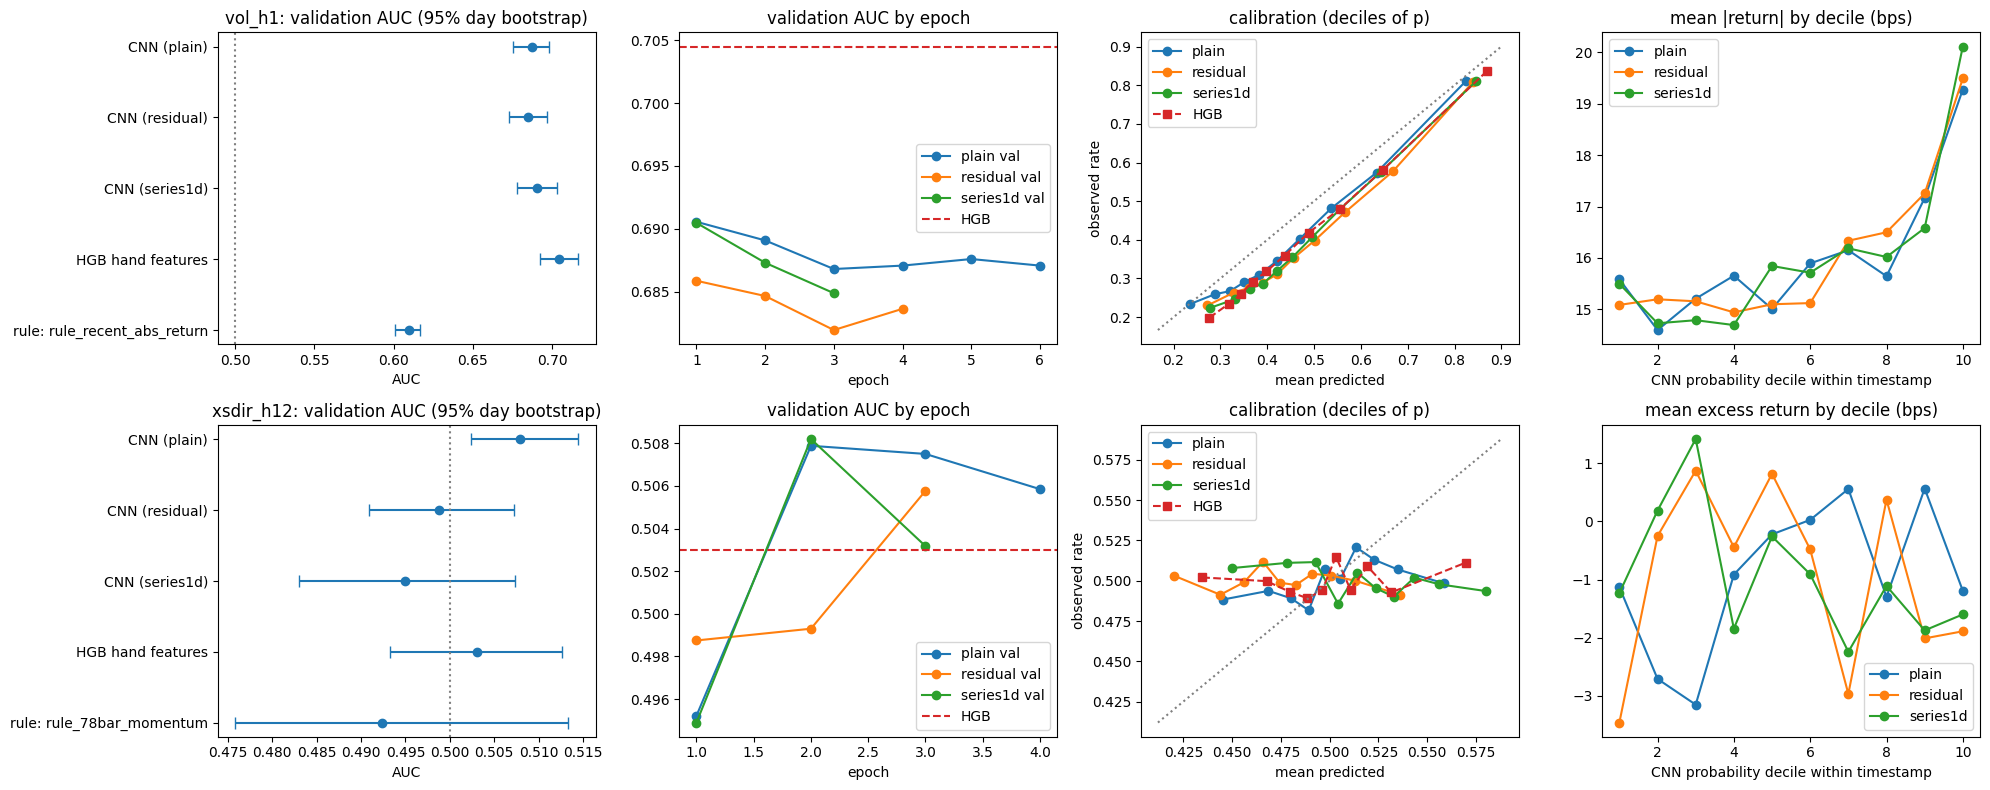

**vol_h1** — best CNN is CNN (plain): AUC 0.687 [0.676, 0.698], above a coin flip.
- Residual − plain AUC: -0.0024 [-0.0050, +0.0008] → no significant difference (residual has 2.6× the parameters).
- CNN (plain) − 1D CNN on raw OHLCV (AUC 0.690): -0.0033 [-0.0078, +0.0009] → no significant difference: the picture adds nothing measurable.
- CNN (plain) − HGB AUC: -0.0171 [-0.0216, -0.0121] → HGB beats CNN.
- Probabilities: log loss +11.4% vs training prior; mean predicted − observed = +0.049 (calibration shift between train and validation).

**xsdir_h12** — best CNN is CNN (plain): AUC 0.508 [0.502, 0.514], above a coin flip.
- Residual − plain AUC: -0.0093 [-0.0167, -0.0013] → plain is better (residual has 2.6× the parameters).
- CNN (plain) − 1D CNN on raw OHLCV (AUC 0.495): +0.0126 [+0.0027, +0.0217] → the image helps.
- CNN (plain) − HGB AUC: +0.0048 [-0.0037, +0.0145] → CNN and HGB are tied.
- Probabilities: log loss -0.2% vs training prior; mean predicted − observed = +0.002.
- Top-minus-bottom decile: -0.34 bps per 12 bars, t = -0.20 (gross; |t| < 2 means no reliable spread).

In [ ]:
from IPython.display import Markdown
PARAMS = {a: sum(p.numel() for p in chartcnn.build_model(dict(SETTINGS, arch=a)).parameters()) for a in ARCHS}
ANALYSIS, BOOTS = analysis.summary_table(RESULTS, PARAMS, n_boot=50 if SMOKE else 300)
display(ANALYSIS.round(4)); ANALYSIS.to_csv(RUN_LOCAL / "analysis.csv")
analysis.plot_analysis(RESULTS, ANALYSIS, RUN_LOCAL / "analysis.png")
TAKEAWAYS = analysis.takeaways(RESULTS, ANALYSIS, BOOTS)
(RUN_LOCAL / "takeaways.md").write_text(TAKEAWAYS); display(Markdown(TAKEAWAYS))
for name in ("analysis.csv", "analysis.png", "takeaways.md"):
    shutil.copy2(RUN_LOCAL / name, RUN_DRIVE / name)

## 8. Frame correlation (model)
Same anchors as section 4, now seen through each trained CNN: correlation of feature maps (`_embed`) and of predictions (`_prob`) between frame *t* and *t+k*.

vol_h1_plain: 776,450 parameters (776,450 trainable)
vol_h1_residual: 2,047,362 parameters (2,047,362 trainable)
xsdir_h12_plain: 776,450 parameters (776,450 trainable)
xsdir_h12_residual: 2,047,362 parameters (2,047,362 trainable)


,lag,bars_shared,pixel_raw,pixel_aligned,vol_h1_plain_embed,vol_h1_plain_prob,vol_h1_residual_embed,vol_h1_residual_prob,xsdir_h12_plain_embed,xsdir_h12_plain_prob,xsdir_h12_residual_embed,xsdir_h12_residual_prob
0,1,77,0.472,0.942,0.414,0.798,0.519,0.874,0.466,0.593,0.559,0.674
1,2,76,0.348,0.893,0.327,0.753,0.449,0.830,0.375,0.258,0.491,0.441
2,3,75,0.294,0.851,0.279,0.687,0.405,0.741,0.332,0.065,0.445,0.281
3,6,72,0.226,0.745,0.232,0.580,0.320,0.627,0.275,0.263,0.356,0.326
4,12,66,0.170,0.616,0.158,0.323,0.209,0.337,0.194,0.066,0.237,0.221
5,24,54,0.132,0.473,0.085,-0.090,0.102,-0.052,0.115,0.129,0.120,0.015
6,39,39,0.115,0.335,0.044,-0.385,0.057,-0.411,0.077,0.018,0.072,0.003
7,78,0,0.158,NaN,0.147,0.613,0.096,0.632,0.113,0.118,0.083,0.168
8,156,0,0.154,NaN,0.138,0.644,0.081,0.684,0.099,-0.083,0.064,0.052


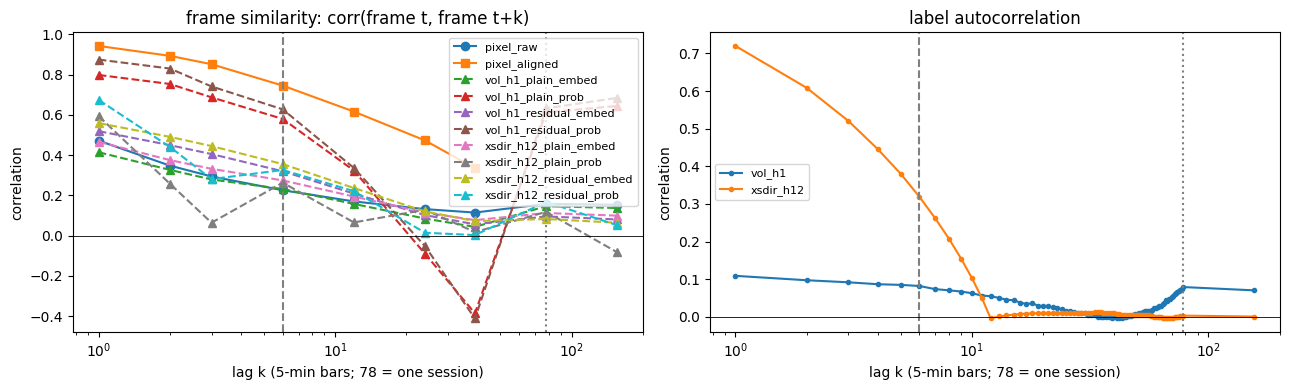

In [ ]:
trained = {}
for key in RESULTS:
    if chartcnn.INPUT_KIND[key.rsplit("_", 1)[1]] != "image":
        continue                                  # frame similarity is defined on images
    m = chartcnn.build_model(dict(SETTINGS, arch=key.rsplit("_", 1)[1]))
    m.load_state_dict(torch.load(RUN_LOCAL / key / "best.pt", map_location="cpu", weights_only=False)["model"])
    chartcnn.print_parameter_count(m, key)
    trained[key] = m
similarity = frame_corr.image_similarity(PREPARED, anchors, LAGS, models=trained, device=DEVICE)
display(similarity.round(3))
plots.plot_frame_corr(similarity, label_acf, SETTINGS["stride"], RUN_LOCAL / "frame_corr_model.png")
similarity.to_csv(RUN_LOCAL / "frame_similarity.csv", index=False)

## 9. Held-out test (off by default)
May–June 2023 has been looked at before, so it is no longer a clean holdout. Run once, after the protocol is frozen.

In [ ]:
RUN_TEST = False
for exp in EXPERIMENTS if RUN_TEST else []:
    for arch in ARCHS:
        key = f"{exp['name']}_{arch}"
        r = RESULTS[key]
        out = evaluate_test(PREPARED, exp, dict(SETTINGS, arch=arch), DEVICE, RUN_LOCAL / key,
                            r["median"], r["prior"], RUN_DRIVE / key, smoke=SMOKE)
        print(key); display(pd.Series(out["test"]).round(4)); print("long-short:", out["long_short"])

## 10. Save

In [ ]:
archive = shutil.make_archive(str(LOCAL / "results"), "zip", root_dir=RUN_LOCAL)
shutil.copy2(archive, RUN_DRIVE / "results.zip")
print("saved", RUN_DRIVE / "results.zip", "| RUN_ID:", RUN_ID)

saved /content/drive/MyDrive/Colab Notebooks/EC/Project/Demo/CNN-Relevant/runs/run_20261114_020923/results.zip | RUN_ID: run_20261114_020923
